In [ ]:
import os
from astropy.table import Table, vstack
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii
import numpy as np
%pylab inline
import matplotlib
import matplotlib.patches as mpatches

from lsst.daf.persistence import Butler
import lsst.afw.image as afwImage
import lsst.afw.table as afwTable
import lsst.afw.image as afwImage
import lsst.afw.display as afwDisplay
import lsst.geom as afwGeom
from lsst.meas.base.noiseReplacer import NoiseReplacerConfig,NoiseReplacer
import lsst.analysis.deblender as deblender

#butler16 = Butler('./homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/')
#butler18 = Butler('./homeDir/data/hsc_ssp/dr2/s18a/data/test/s18a_wide_revpsf/')
butler19 = Butler('./homeDir/data/hsc_ssp/dr3/s19a/data/s19a_wide/')

bandList='gri'
plt.rcParams['figure.figsize'] = (15, 15)

In [ ]:
def findInAperture(centList,radius,cat):
    """Return the objects within Aperture"""
    oneObjCatalog = afwTable.SourceCatalog(cat.getSchema())
    centroidName = cat.table.getCentroidDefinition()
    oneObjCatalog.table.defineCentroid(centroidName)

    for cent in centList:
        x, y = cent.getX(), cent.getY()
        s = oneObjCatalog.addNew()
        s.set("%s_x" % centroidName, x)
        s.set("%s_y" % centroidName, y)

    return afwTable.matchXy(cat, oneObjCatalog, radius)

def get_imag_color(source):
    flux=source.getModelInstFlux()
    if flux>0:
        mag=-2.5 * np.log10(flux) + 27.
    else:
        mag=27.
    if mag>25.5:
        return afwDisplay.RED
    elif mag > 24.5:
        return afwDisplay.ORANGE
    elif mag > 23.5:
        return afwDisplay.YELLOW
    elif mag > 22.5:
        return afwDisplay.GREEN
    elif mag > 21.5:
        return afwDisplay.BLUE

# Case 1: unrecongnized potential blending !

In [2]:
cat=Table.read('wrkDir/exfaGalAll-noiRep-srcInser/s16/cat-0.csv')

In [6]:
img16=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s16/gal-0.fits')
img18=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s18/gal-0.fits')
img19=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s19/gal-0.fits')

imgO16=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-0.fits')
imgO18=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-0.fits')
imgO19=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-0.fits')

mskO16=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-0.fits').astype(int)
mskO18=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-0.fits').astype(int)
mskO19=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-0.fits').astype(int)

msk16=(np.bitwise_and(mskO16,32))*1.
msk18=(np.bitwise_and(mskO18,32))*1.
msk19=(np.bitwise_and(mskO19,32))*1.

bad16=((mskO16!=0) & (mskO16!=32))*10.
bad18=((mskO18!=0) & (mskO18!=32))*10.
bad19=((mskO19!=0) & (mskO19!=32))*10.

imgO162=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-1.fits')
imgO182=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-1.fits')
imgO192=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-1.fits')

msk162=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-1.fits').astype(int)
msk182=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-1.fits').astype(int)
msk192=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-1.fits').astype(int)

mat16=Table.read('wrkDir/exfaGalAll/s16/mat-0.csv')
mat18=Table.read('wrkDir/exfaGalAll/s18/mat-0.csv')
mat19=Table.read('wrkDir/exfaGalAll/s19/mat-0.csv')

def makePlot3(i):
    ss=cat[i]
    print(ss['ra'],ss['dec'],ss['TPid'])
    mm16=mat16[mat16['id1']==i]
    mm18=mat18[mat18['id1']==i]
    mm19=mat19[mat19['id1']==i]
    def drawCircle(mms):
        for ms in mms:
            if ms['dx']**2.+ms['dy']**2.<150.:
                mxy=(ngrid//2+ms['dx'],ngrid//2+ms['dy'])
                mrg=min(ms['traceR']/0.168,ngrid//2)
                mclr =   cmap(norm(ms['mag']))
                mcir =   mpatches.Circle(mxy,radius=mrg,ls='-',facecolor='None',edgecolor=mclr,lw=3.)
                ax.add_patch(mcir)
        return
    
    
    ngrid=64
    xy  =   (ngrid//2,ngrid//2)
    cmap    =   plt.cm.Paired
    norm    =   matplotlib.colors.Normalize(vmin=21,vmax=25.)
    mappable=   plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array([])

    fig =   plt.figure(figsize=(15, 11))

    ax  =   fig.add_subplot(2,3,1)
    ax.set_title('S16A',fontsize=20)
    drawCircle(mm16)
    ax.imshow(img16[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,2)
    ax.set_title('S18A',fontsize=20)
    drawCircle(mm18)
    ax.imshow(img18[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,3)
    ax.set_title('S19A',fontsize=20)
    drawCircle(mm19)
    ax.imshow(img19[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,4)
    drawCircle(mm16)
    ax.imshow(msk16[i]+bad16[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,5)
    drawCircle(mm18)
    ax.imshow(msk18[i]+bad18[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,6)
    drawCircle(mm19)
    ax.imshow(msk19[i]+bad19[i],origin='lower',cmap='Greys_r')
    
    cbar_ax     =   fig.add_axes([0.12, 0.1, 0.78, 0.01])
    fig.colorbar(mappable,cbar_ax,orientation='horizontal')
    plt.show()
    return fig

def makePlot4():
    bg16=[]
    bg18=[]
    bg19=[]
    for j in range(len(il)):
        i=il[j]
        mask1=(msk19[i]==0)& (msk18[i]==0) & (msk16[i]==0)
        bg16.extend(imgO16[i][mask1])
        bg18.extend(imgO18[i][mask1])
        bg19.extend(imgO19[i][mask1])
        mask2=(msk192[i]==0)& (msk182[i]==0) & (msk162[i]==0)
        bg16.extend(imgO162[i][mask2])
        bg18.extend(imgO182[i][mask2])
        bg19.extend(imgO192[i][mask2])

    h,g=np.histogram(bg16,30)
    ave=np.average(bg16)
    axvline(ave,c='red',ls='--')
    plt.plot(g[:-1],h,'--',label='s16A',c='red')
    h,g=np.histogram(bg18,g)
    ave=np.average(bg18)
    axvline(ave,c='blue',ls='-')
    plt.plot(g[:-1],h,'-',label='s18A',c='blue')
    h,g=np.histogram(bg19,g)
    ave=np.average(bg19)
    axvline(ave,c='black',ls='-.')
    plt.plot(g[:-1],h,'-.',label='s19A',c='black')
    plt.xlabel('pixel value')
    plt.ylabel('num')
    plt.yscale('log')
    plt.legend()
    return

240.56146077630922 43.14520925893637 16007200


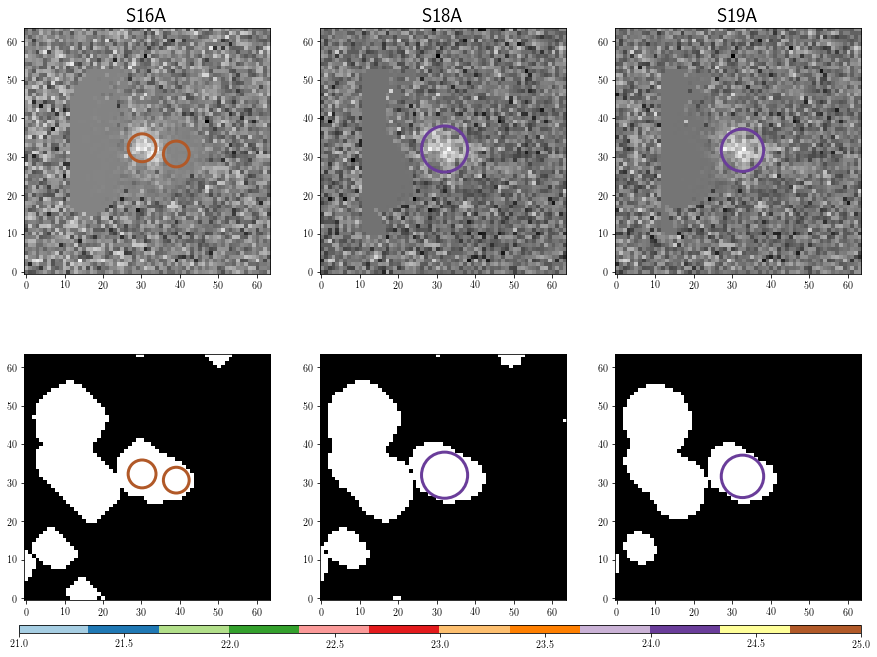

In [10]:
from IPython.display import clear_output
import time
j=0
il=[3,4,12,13,16,20,21,25,27,32,33,37,40,0,2,41,43,48,50,10,11,18,24,52,53,54,55,56,57,58,59,60,61,62,63,67,68,70,71,73,74]
i=il[j]
fig=makePlot3(i)

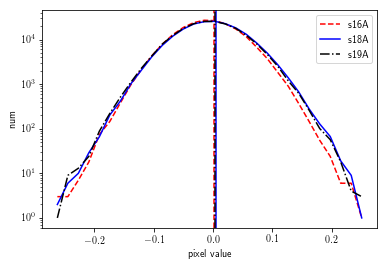

In [8]:
makePlot4()

* larger resolution
* brighter magnitude
* more sources (\# S19 < \# S16)

In [9]:
noiConfig   =   NoiseReplacerConfig()
il=[3,4,12,13,16,21,25,27,32,33,37,40,0,2,41,43,48,50,10,11,18,24,52,53,54,55,56,57,58,59,60,61,62,63,67,68,70,71,73,74]

# isolike
#il=[1,29,31,35,37,39,42,44,45,46,47,49,64,64,65]
# load data
catDis=cat[il]
tpIdSet=list(set(catDis['TPid']))

In [10]:
afwDisplay.setDefaultBackend('firefly')
for ii in range(2,3):
    catTest=catDis[ii]
    TPid=catTest['TPid']

    expDict16={}
    expDict19={}
    srcDict16={}
    srcDict19={}
    for band in bandList:
        dataId = {'filter': 'HSC-%s' %band.upper(), 'tract': TPid//1000, 'patch': '%d,%d' %(TPid%1000/100,TPid%100%100)}

        expN16 = butler16.get('deepCoadd_calexp_filename', **dataId)[0].split('-results/')[1]
        expN16=os.path.join('/work/xiangchong.li/superonionGW/code/G3sim-s18a/notebook/susGal/homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/deepCoadd',expN16)
        expDict16[band]=afwImage.ExposureF(expN16)
        srcDict16[band]=butler16.get('deepCoadd_meas',**dataId)
        expDict19[band]=butler19.get('deepCoadd_calexp', **dataId)
        srcDict19[band]=butler19.get('deepCoadd_meas',**dataId)

    exp16=expDict16['i']
    src16=srcDict16['i']
    fam16=deblender.Families(src16,nChildMin=0)
    srcbs=fam16.find(catTest['object_id16'],10)
    parent16=srcbs[0]
    children16=srcbs[1]

    exp19=expDict19['i']
    src19=srcDict19['i']
    fam19=deblender.Families(src19,nChildMin=0)
    srcbs=fam19.find(catTest['object_id19'],10)
    parent19=srcbs[0]
    children19=srcbs[1]
    iframe=1
    display = afwDisplay.getDisplay(frame=iframe,reopenPlot=True)
    display.setMaskPlaneColor('detect-g', afwDisplay.BLUE)
    display.setMaskPlaneColor('detect-r', afwDisplay.CYAN)
    display.setMaskPlaneColor('detect-i', afwDisplay.YELLOW)
    display.setMaskTransparency(80)
    display.scale("equal", "minmax")

    nameNchild = "deblend_nchild"
    mos=afwDisplay.utils.Mosaic()

    cc=afwGeom.Point2I(parent16.getCentroid())
    showR=80
    extU=afwGeom.Extent2I(showR,showR)
    boxU=afwGeom.Box2I(cc-extU,2*extU)
    boxU.clip(exp16.getBBox())
    
    neiSrc16=findInAperture([cc],showR*1.5,src16)

    imgShow=afwImage.MaskedImageF(boxU)
    imgShow.getImage().getArray()[:,:]=exp16.getImage()[boxU].getArray()[:,:]

    maskN=afwImage.Mask(boxU)
    for band in bandList:
        pName='detect-%s' %band
        maskN.addMaskPlane(pName)
        ratio=maskN.getPlaneBitMask(pName)//32
        maskN.getArray()[:,:]+=np.int_(np.bitwise_and(expDict16[band][boxU].getMask().getArray(),32)*ratio)
    imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]

    mos.append(imgShow)
    del imgShow

    fp16  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in src16}
    nrper16=  NoiseReplacer(noiConfig, exp16, fp16)
    for ss in children16:
        nrper16.insertSource(ss.getId())
        imgShow=afwImage.MaskedImageF(boxU)
        imgShow.getImage().getArray()[:,:]=exp16.getImage()[boxU].getArray()[:,:]
        imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
        mos.append(imgShow)
        del imgShow
        nrper16.removeSource(ss.getId())

    mos.makeMosaic(display=display,title='S16A')

    point0=boxU.getBegin()
    with display.Buffering(): 
        label='+'
        dcc=mos.getBBox(0).getMin()-point0
        for ss in [parent16]+children16:
            if ss[nameNchild]==0:
                cc=ss.getCentroid()
                cc+=dcc
                display.dot(label,cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))
        for mm in neiSrc16:
            ss=mm[0]
            if (ss[nameNchild]==0) and (ss.getParent()!=parent16.getId()) and (ss.getId()!=parent16.getId()):
                cc=ss.getCentroid()
                cc+=dcc
                if cc.getX()<0 or cc.getY()<0 or cc.getX()>2*showR or cc.getY()>2*showR:
                    continue
                display.dot('o',cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))
        for iss,ss in enumerate(children16):
            dcc=mos.getBBox(iss+1).getMin()-point0
            cc=ss.getCentroid()
            cc+=dcc
            display.dot(label,cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))

    #display.savefig('./wrkDir/exfaGalAll/plot/S16-blendlike-ID_%d.png' %(il[ii]))
    
    iframe=2
    display = afwDisplay.getDisplay(frame=iframe,reopenPlot=True)
    display.setMaskPlaneColor('detect-g', afwDisplay.BLUE)
    display.setMaskPlaneColor('detect-r', afwDisplay.CYAN)
    display.setMaskPlaneColor('detect-i', afwDisplay.YELLOW)
    display.setMaskTransparency(80)
    display.scale("equal", "minmax")

    nameNchild = "deblend_nChild"
    mos=afwDisplay.utils.Mosaic()

    cc=afwGeom.Point2I(parent19.getCentroid())
    extU=afwGeom.Extent2I(showR,showR)
    boxU=afwGeom.Box2I(cc-extU,2*extU)
    boxU.clip(exp19.getBBox())
    
    neiSrc19=findInAperture([cc],showR*1.5,src19)
    
    imgShow=afwImage.MaskedImageF(boxU)
    imgShow.getImage().getArray()[:,:]=exp19.getImage()[boxU].getArray()[:,:]
    maskN=afwImage.Mask(boxU)
    for band in bandList:
        pName='detect-%s' %band
        maskN.addMaskPlane(pName)
        ratio=maskN.getPlaneBitMask(pName)//32
        maskN.getArray()[:,:]+=np.int_(np.bitwise_and(expDict19[band][boxU].getMask().getArray(),32)*ratio)
    imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
    mos.append(imgShow)
    del imgShow

    fp19  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in src19}
    nrper19=  NoiseReplacer(noiConfig, exp19, fp19)
    for ss in children19:
        nrper19.insertSource(ss.getId())
        imgShow=afwImage.MaskedImageF(boxU)
        imgShow.getImage().getArray()[:,:]=exp19.getImage()[boxU].getArray()[:,:]
        imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
        mos.append(imgShow)
        del imgShow
        nrper19.removeSource(ss.getId())

    mos.makeMosaic(display=display,title='S19A')

    point0=boxU.getBegin()
    with display.Buffering(): 
        label='+'
        dcc=mos.getBBox(0).getMin()-point0
        for ss in [parent19]+children19:
            if ss[nameNchild]==0:
                cc=ss.getCentroid()
                cc+=dcc
                display.dot(label,cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))
        for mm in neiSrc19:
            ss=mm[0]
            if (ss[nameNchild]==0) and (ss.getParent()!=parent19.getId()) and (ss.getId()!=parent19.getId()):
                cc=ss.getCentroid()
                cc+=dcc
                if cc.getX()<0 or cc.getY()<0 or cc.getX()>2*showR or cc.getY()>2*showR:
                    continue
                display.dot('o',cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))
        for iss,ss in enumerate(children19):
            dcc=mos.getBBox(iss+1).getMin()-point0
            cc=ss.getCentroid()
            cc+=dcc
            display.dot(label,cc.getX(),cc.getY(), size=2, ctype=get_imag_color(ss))
    #display.savefig('./wrkDir/exfaGalAll/plot/S19-blendlike-ID_%d.png' %(il[ii]))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:4: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
  after removing the cwd from sys.path.
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:4: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
  after removing the cwd from sys.path.


In [ ]:
parent16.getModelInstFlux

245.3816870390777 43.12196037186333 15831108


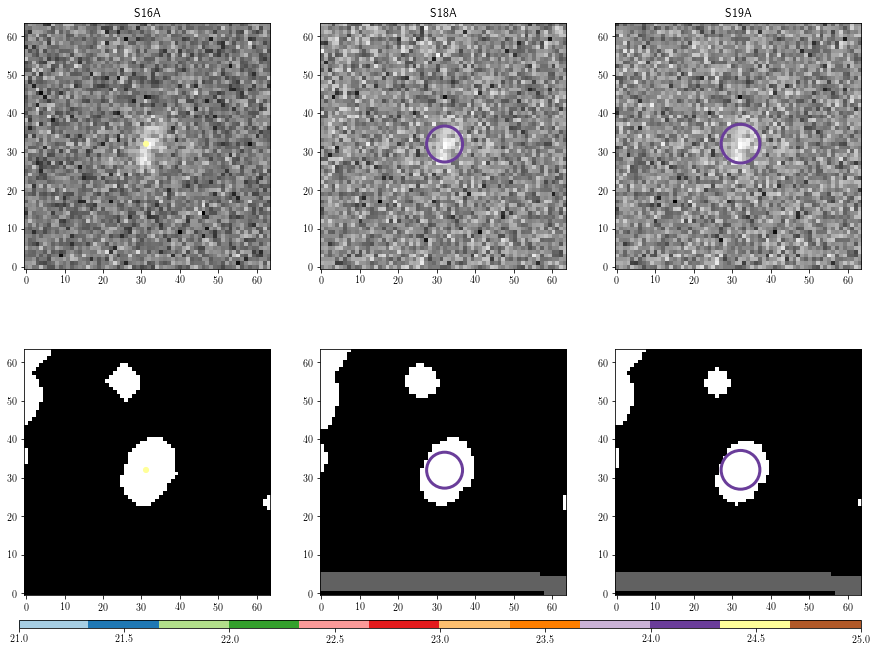

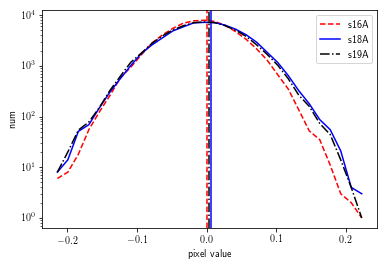

In [123]:
j=1
il=[1,29,31,35,37,39,42,44,45,46,47,49,64,64,65]
i=il[j]
fig=makePlot3(i)
makePlot4()

In [3]:
noiConfig   =   NoiseReplacerConfig()

il=[1,29,31,35,37,39,42,44,45,46,47,49,64,64,65]
catDis=cat[il]
tpIdSet=list(set(catDis['TPid']))

In [4]:
afwDisplay.setDefaultBackend('firefly')
for ii in range(0,1):
    catTest=catDis[ii]
    TPid=catTest['TPid']

    expDict16={}
    expDict19={}
    srcDict16={}
    srcDict19={}
    for band in bandList:
        dataId = {'filter': 'HSC-%s' %band.upper(), 'tract': TPid//1000, 'patch': '%d,%d' %(TPid%1000/100,TPid%100%100)}

        expN16 = butler16.get('deepCoadd_calexp_filename', **dataId)[0].split('-results/')[1]
        expN16=os.path.join('/work/xiangchong.li/superonionGW/code/G3sim-s18a/notebook/susGal/homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/deepCoadd',expN16)
        expDict16[band]=afwImage.ExposureF(expN16)
        srcDict16[band]=butler16.get('deepCoadd_meas',**dataId)
        expDict19[band]=butler19.get('deepCoadd_calexp', **dataId)
        srcDict19[band]=butler19.get('deepCoadd_meas',**dataId)

    exp16=expDict16['i']
    src16=srcDict16['i']
    fam16=deblender.Families(src16,nChildMin=0)
    srcbs=fam16.find(catTest['object_id16'],10)
    parent16=srcbs[0]
    children16=srcbs[1]

    exp19=expDict19['i']
    src19=srcDict19['i']
    fam19=deblender.Families(src19,nChildMin=0)
    srcbs=fam19.find(catTest['object_id19'],10)
    parent19=srcbs[0]
    children19=srcbs[1]
    iframe=1
    display = afwDisplay.getDisplay(frame=iframe,reopenPlot=True)
    display.setMaskPlaneColor('detect-g', afwDisplay.BLUE)
    display.setMaskPlaneColor('detect-r', afwDisplay.CYAN)
    display.setMaskPlaneColor('detect-i', afwDisplay.YELLOW)
    display.setMaskTransparency(80)
    display.scale("equal", "minmax")

    nameNchild = "deblend_nchild"
    mos=afwDisplay.utils.Mosaic()

    cc=afwGeom.Point2I(parent16.getCentroid())
    showR=80
    extU=afwGeom.Extent2I(showR,showR)
    boxU=afwGeom.Box2I(cc-extU,2*extU)
    boxU.clip(exp16.getBBox())
    
    neiSrc16=findInAperture([cc],showR*1.5,src16)

    imgShow=afwImage.MaskedImageF(boxU)
    imgShow.getImage().getArray()[:,:]=exp16.getImage()[boxU].getArray()[:,:]

    maskN=afwImage.Mask(boxU)
    for band in bandList:
        pName='detect-%s' %band
        maskN.addMaskPlane(pName)
        ratio=maskN.getPlaneBitMask(pName)//32
        maskN.getArray()[:,:]+=np.int_(np.bitwise_and(expDict16[band][boxU].getMask().getArray(),32)*ratio)
    imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]

    mos.append(imgShow)
    del imgShow

    fp16  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in src16}
    nrper16=  NoiseReplacer(noiConfig, exp16, fp16)
    for ss in children16:
        nrper16.insertSource(ss.getId())
        imgShow=afwImage.MaskedImageF(boxU)
        imgShow.getImage().getArray()[:,:]=exp16.getImage()[boxU].getArray()[:,:]
        imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
        mos.append(imgShow)
        del imgShow
        nrper16.removeSource(ss.getId())

    mos.makeMosaic(display=display,title='S16A')

    point0=boxU.getBegin()
    add_notation(display,mos,parent16,children16,point0,neiSrc16)

    #display.savefig('./wrkDir/exfaGalAll/plot/S16-blendlike-ID_%d.png' %(il[ii]))
    
    iframe=2
    display = afwDisplay.getDisplay(frame=iframe,reopenPlot=True)
    display.setMaskPlaneColor('detect-g', afwDisplay.BLUE)
    display.setMaskPlaneColor('detect-r', afwDisplay.CYAN)
    display.setMaskPlaneColor('detect-i', afwDisplay.YELLOW)
    display.setMaskTransparency(80)
    display.scale("equal", "minmax")

    nameNchild = "deblend_nChild"
    mos=afwDisplay.utils.Mosaic()

    cc=afwGeom.Point2I(parent19.getCentroid())
    extU=afwGeom.Extent2I(showR,showR)
    boxU=afwGeom.Box2I(cc-extU,2*extU)
    boxU.clip(exp19.getBBox())
    
    neiSrc19=findInAperture([cc],showR*1.5,src19)
    
    imgShow=afwImage.MaskedImageF(boxU)
    imgShow.getImage().getArray()[:,:]=exp19.getImage()[boxU].getArray()[:,:]
    maskN=afwImage.Mask(boxU)
    for band in bandList:
        pName='detect-%s' %band
        maskN.addMaskPlane(pName)
        ratio=maskN.getPlaneBitMask(pName)//32
        maskN.getArray()[:,:]+=np.int_(np.bitwise_and(expDict19[band][boxU].getMask().getArray(),32)*ratio)
    imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
    mos.append(imgShow)
    del imgShow

    fp19  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in src19}
    nrper19=  NoiseReplacer(noiConfig, exp19, fp19)
    for ss in children19:
        nrper19.insertSource(ss.getId())
        imgShow=afwImage.MaskedImageF(boxU)
        imgShow.getImage().getArray()[:,:]=exp19.getImage()[boxU].getArray()[:,:]
        imgShow.getMask().getArray()[:,:]=maskN.getArray()[:,:]
        mos.append(imgShow)
        del imgShow
        nrper19.removeSource(ss.getId())

    mos.makeMosaic(display=display,title='S19A')

    point0=boxU.getBegin()
    add_notation(display,mos,parent19,children19,point0,neiSrc19)
    #display.savefig('./wrkDir/exfaGalAll/plot/S19-blendlike-ID_%d.png' %(il[ii]))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:70: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:70: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)


# Case 3 Extreme Case

0.13
244.36246659401098 43.433764958215015 16009302


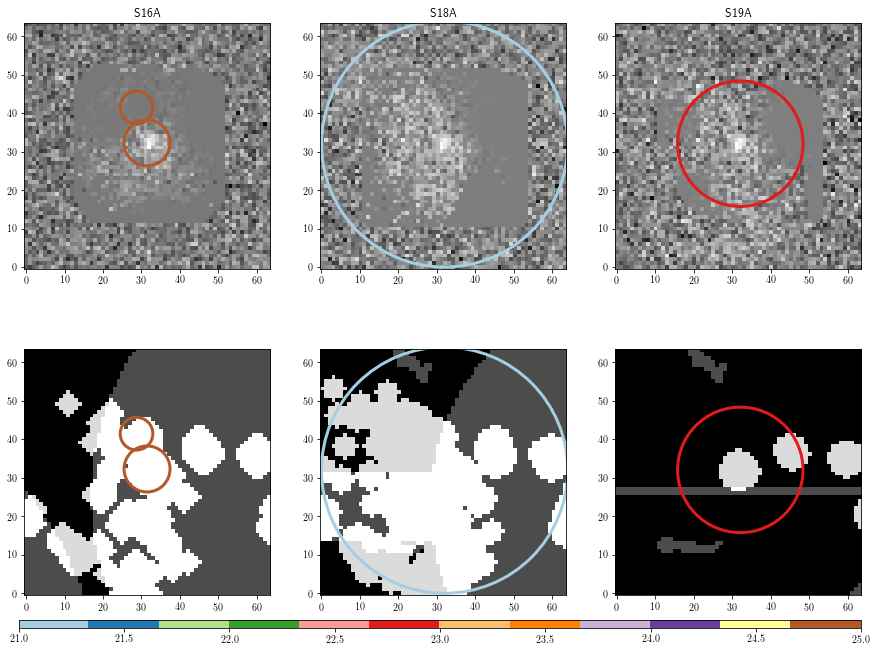

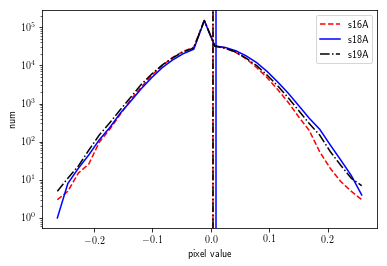

In [11]:
il=np.where((cat['mag16']-cat['mag'])>2.5)[0]
print(len(il)/len(cat))
j=2
i=il[j]
makePlot3(i)
makePlot4()

In [12]:
a=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s18.fits')
b=pyfits.getdata('./wrkDir/database/compare/scat-s18-unmatch-s16.fits')
a2=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s19.fits')

In [13]:
maskA=(a['mag']<19)&(a['res']>0.3)&(a['logb']<-0.38)&(a['TPid']==9696502)
maskB=(b['mag']<19)&(b['res']>0.3)&(b['logb']<-0.38)&(b['TPid']==9696502)
maskA2=(a2['mag']<19)&(a2['res']>0.3)&(a2['logb']<-0.38)&(a2['TPid']==9696502)
aM=a[maskA]
bM=b[maskB]
aM2=a2[maskA2]

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in less
  """Entry point for launching an IPython kernel.
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:2: RuntimeWarning: invalid value encountered in less
  
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in less
  This is separate from the ipykernel package so we can avoid doing imports until


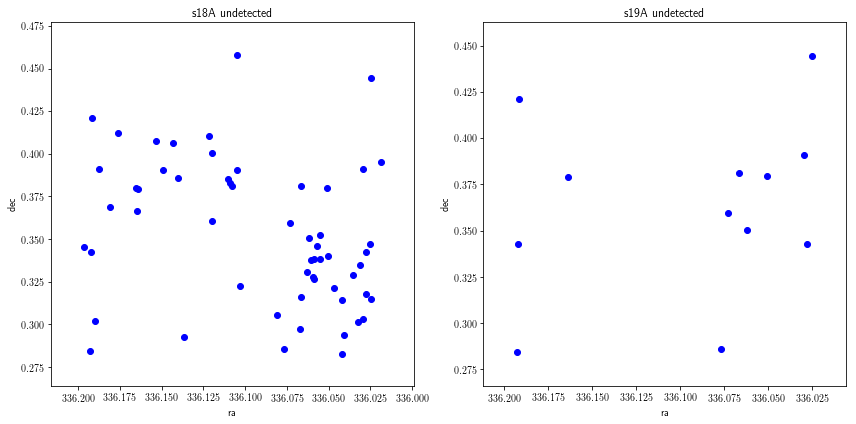

In [14]:
fig=    plt.figure(figsize=(12, 6))
ax =    fig.add_subplot(1,2,1)
ax.scatter(aM['ra'],aM['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s18A undetected')
ax =    fig.add_subplot(1,2,2)
ax.scatter(aM2['ra'],aM2['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s19A undetected')
plt.tight_layout()